# Data processing for the CS224W project

From the mcPHASES v1.0.0 files to the model inputs. This notebook reads the outputs of
`preprocess_cs224w.py`.
It shows each step on the 2022 data, the main version. Every number is computed here.

Only summaries over all participants are shown, never one person's data: the mcPHASES licence doesn't allow
sharing participant-level data. The reason for each step is in `preprocessing_decisions.md`; the numbers in
brackets refer to its sections.

1. The data used
2. Cleaning
3. The daily table
4. Targets
5. Scaling and missing values
6. Modality nodes
7. Output

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

OUT = Path("output")
FIG = Path("figures"); FIG.mkdir(exist_ok=True)
t = pd.read_csv(OUT / "daily_table_2022_only.csv")
if Path(OUT / "feature_modalities.csv").exists():
    fm = pd.read_csv(OUT / "feature_modalities.csv")
else:   # preprocess_cs224w.py: the feature list is stored in graph_inputs.npz
    _g = np.load(OUT / "cs224w_2022_only" / "graph_inputs.npz")
    fm = pd.DataFrame([{"feature": f, "modality": m, "source": {"glucose": "CGM", "symptoms": "diary"}.get(m, "Fitbit")}
                       for m, names in zip(_g["modalities"], _g["feature_names"]) for f in names if f])
cleaning = pd.read_csv(OUT / "cleaning_summary_2022_only.csv")
feats = list(fm.feature)
hormone_days = t[t.lh.notna() | t.estrogen.notna()]
TEXT, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
BLUE, ORANGE, GREEN, AMBER, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#9a9893"
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": GRID, "axes.grid": True,
    "grid.color": GRID, "axes.spines.top": False, "axes.spines.right": False, "axes.titlelocation": "left",
    "axes.titlesize": 11, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 9, "figure.dpi": 110})
def save(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")

## 1. The data used [1]

The 2022 round only (all 42 participants). Eight mcPHASES files provide the inputs. The hormone and diary file
provides the targets (LH and E3G from Mira urine tests) and the symptoms.

In [2]:
summary = pd.DataFrame({
    "participants": [hormone_days.id.nunique()],
    "person-days in the table": [len(t)],
    "days with LH": [int(t.lh.notna().sum())],
    "days with E3G": [int(t.estrogen.notna().sum())],
    "days per participant (median)": [int(t.groupby("id").size().median())]})
display(summary.T.rename(columns={0: "2022"}))

,2022
participants,42
person-days in the table,3698
days with LH,3472
days with E3G,3471
days per participant (median),90


## 2. Cleaning [2]

What each cleaning step changed in 2022. These are fixes to errors in the raw data (duplicate rows, Fitbit's
"no estimate" codes, mixed glucose units) and published valid-day rules. None of them creates new features.

,rows or days affected
cleaning step,
LH of 0 set to missing,3
E3G of 0 set to missing,3
deduplication: exact copies removed,866
deduplication: rows in disagreeing keys removed,144
main sleep < 180 min removed,112
valid day: heart rate < 10 h of readings,106
resting heart rate of 0 set to missing,782
breathing rate of 0 or -1 set to missing,53
glucose converted from mg/dL to mmol/L,34514


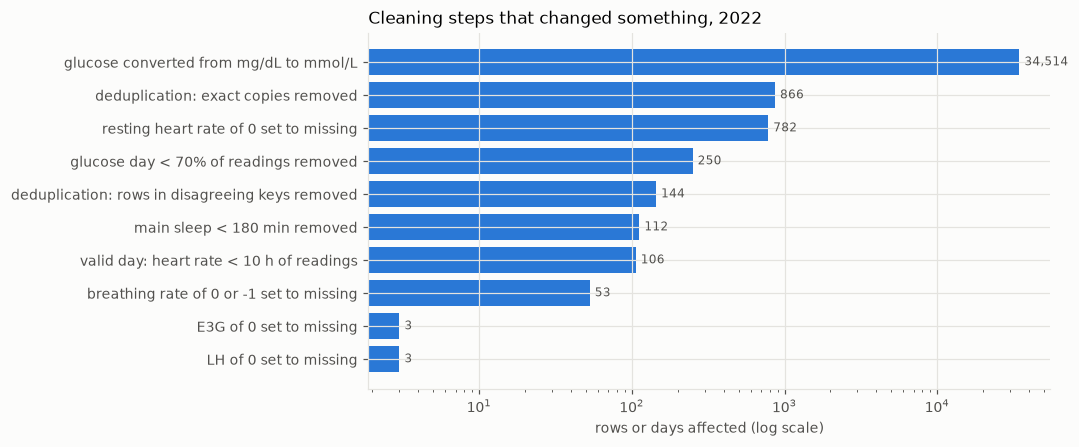

In [3]:
c = cleaning[(cleaning.study_interval == 2022)].copy()
c["what"] = c.step + np.where(c.detail.fillna("") != "", " (" + c.detail.fillna("") + ")", "")
c = c.groupby("step", sort=False).n.sum().reset_index()
display(c.rename(columns={"step": "cleaning step", "n": "rows or days affected"}).set_index("cleaning step"))
shown = c[c.n > 0].sort_values("n")
fig, ax = plt.subplots(figsize=(8, 0.32 * len(shown) + 1))
ax.barh(range(len(shown)), shown.n, color=BLUE)
ax.set_yticks(range(len(shown)), shown.step); ax.set_xscale("log"); ax.set_xlabel("rows or days affected (log scale)")
ax.set_title("Cleaning steps that changed something, 2022")
for i, v in enumerate(shown.n): ax.text(v * 1.08, i, f"{v:,}", va="center", fontsize=8, color=MUTED)
save(fig, "cleaning_steps"); plt.show()

## 3. The daily table [3]

One row per person-day, from each person's first to last diary day, with 29 features in 8 modalities. These are
the features of the team's preliminary code; none are added. Overnight measures (temperature, HRV, breathing rate,
sleep) are on the morning after. The chart shows how often each feature has a value on the days with a hormone
measurement.

,source,feature
modality,,
heart rate,Fitbit,"resting_hr, hr_mean, hr_sd"
nightly temperature,Fitbit,nightly_skin_temperature
heart rate variability,Fitbit,nightly_rmssd
respiratory rate,Fitbit,respiration
sleep,Fitbit,"sleep_minutes, sleep_efficiency"
activity,Fitbit,"light_minutes, moderate_minutes, very_minutes,..."
glucose,CGM,"glucose_mean, glucose_sd, glucose_min, glucose..."
symptoms,diary,"diary_appetite, diary_exerciselevel, diary_hea..."


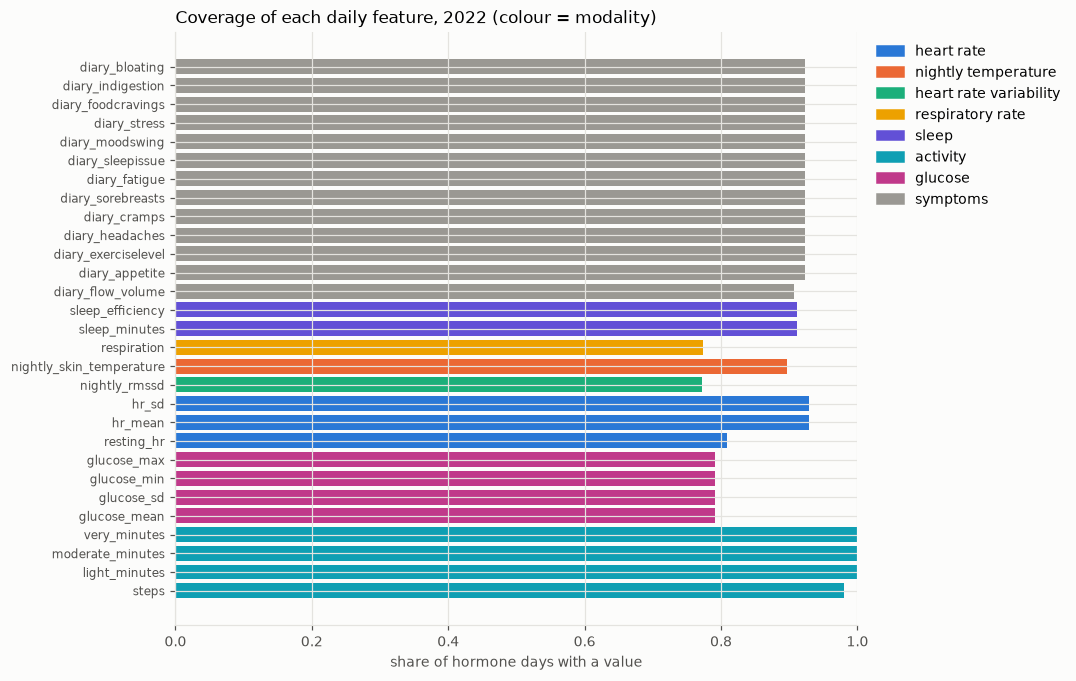

In [4]:
display(fm.groupby(["modality", "source"], sort=False).feature.apply(", ".join).reset_index().set_index("modality"))
cov = hormone_days[feats].notna().mean()
order = fm.assign(cov=cov.values).sort_values(["modality", "cov"])
colors = dict(zip(fm.modality.unique(), [BLUE, ORANGE, GREEN, AMBER, "#6250d6", "#0f9fb3", "#c0398a", GREY]))
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(range(len(order)), order["cov"], color=[colors[m] for m in order.modality])
ax.set_yticks(range(len(order)), order.feature, fontsize=8); ax.set_xlim(0, 1)
ax.set_xlabel("share of hormone days with a value"); ax.set_title("Coverage of each daily feature, 2022 (colour = modality)")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in colors.values()]
ax.legend(handles, colors.keys(), frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1.0))
save(fig, "feature_coverage"); plt.show()

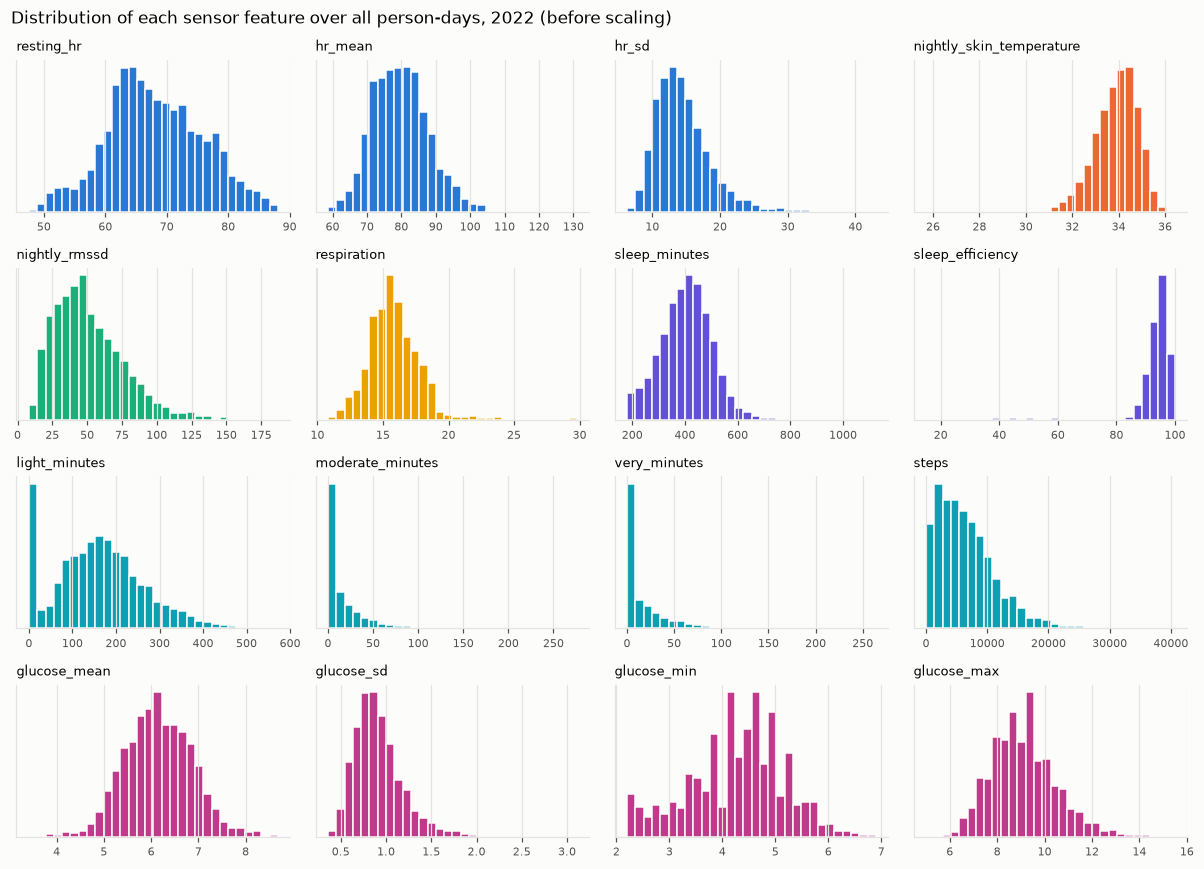

In [5]:
fig, axs = plt.subplots(4, 4, figsize=(11, 8))
sensor = [f for f in feats if not f.startswith("diary_")]
for ax, f in zip(axs.flat, sensor):
    v = t[f].dropna()
    ax.hist(v, bins=30, color=colors[fm.set_index("feature").modality[f]], edgecolor=SURFACE)
    ax.set_title(f, fontsize=8.5); ax.tick_params(labelsize=7); ax.set_yticks([])
for ax in list(axs.flat)[len(sensor):]: ax.axis("off")
fig.suptitle("Distribution of each sensor feature over all person-days, 2022 (before scaling)", x=0.01, ha="left", fontsize=11)
plt.tight_layout(); save(fig, "feature_distributions"); plt.show()

## 4. Targets [1.4, 4.5]

LH and E3G on each measured day, transformed with log(1 + value), as in both proposals. The Mira test reads LH down
to 1.0 and E3G up to 640, and values at those limits are kept (dashed lines).

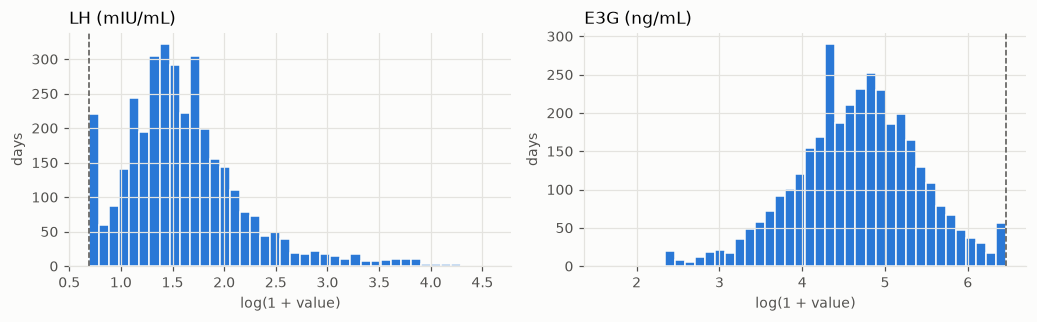

,median,max,share at the test limit (%)
LH,3.6,97.0,5.1
E3G,108.5,640.0,1.2


In [6]:
fig, axs = plt.subplots(1, 2, figsize=(9.5, 3))
for ax, (c, label, limit) in zip(axs, [("lh", "LH (mIU/mL)", 1.0), ("estrogen", "E3G (ng/mL)", 640)]):
    v = np.log1p(t[c].dropna())
    ax.hist(v, bins=40, color=BLUE, edgecolor=SURFACE)
    ax.axvline(np.log1p(limit), color=MUTED, ls="--", lw=1)
    ax.set(title=label, xlabel="log(1 + value)", ylabel="days")
plt.tight_layout(); save(fig, "targets"); plt.show()
display(pd.DataFrame({"median": [t.lh.median(), t.estrogen.median()], "max": [t.lh.max(), t.estrogen.max()],
                      "share at the test limit (%)": [round(100 * (t.lh == 1).sum() / t.lh.notna().sum(), 1),
                                                       round(100 * (t.estrogen == 640).sum() / t.estrogen.notna().sum(), 1)]},
                     index=["LH", "E3G"]))

## 5. Scaling and missing values [4.2, 4.4, 5.3, 5.4]

Each Fitbit and glucose feature is z-scored per participant, using the mean and SD of that person's earlier days
only (from 3 days of history on), then clipped at ±5 SD. No information from later days enters a value. Diary
items are divided by their scale maximum, so they run 0–1. Missing values are not filled: a modality-day with no value becomes a missing node [5.3].

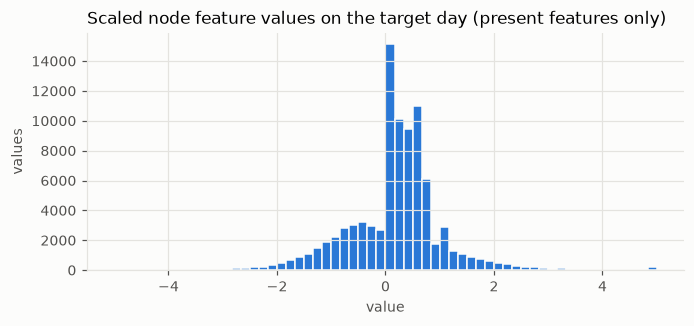

Missing features inside present nodes are 0 with feature_present = 0; nothing is imputed. Share of nodes present: 82.7%


In [7]:
g = np.load(OUT / "cs224w_2022_only" / "graph_inputs.npz")
nf, fp, npres, mods = g["node_features"], g["feature_present"], g["node_present"], list(g["modalities"])
vals = nf[:, -1][fp[:, -1]]
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.hist(vals, bins=60, color=BLUE, edgecolor=SURFACE)
ax.set(title="Scaled node feature values on the target day (present features only)", xlabel="value", ylabel="values")
save(fig, "scaled_values"); plt.show()
print(f"Missing features inside present nodes are 0 with feature_present = 0; nothing is imputed. "
      f"Share of nodes present: {npres.mean():.1%}")

## 6. Modality nodes [5.1, 5.2, 5.3]

One example per hormone day: the 7 days ending on that day, target day included, with 8 modality nodes per day.
A modality-day with no value is a missing node; the graph models leave it out. The chart shows how often each node
is present on each day of the window. Earlier window days are present less often partly because, for the first
days of a round, the window reaches back before the round starts. Edges (same-day, same-modality across days, different modalities across
days) are built in the model code from this grid.

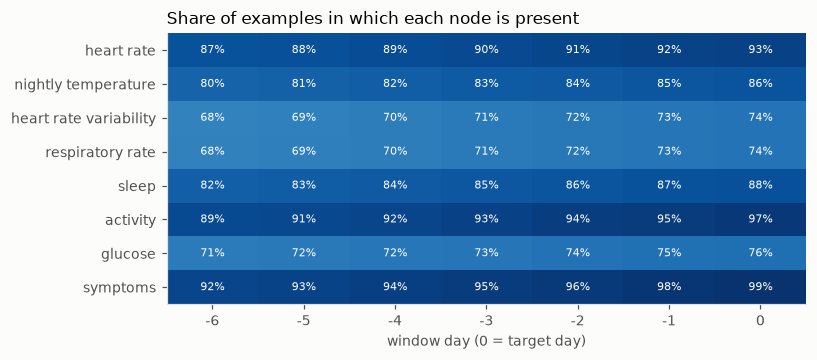

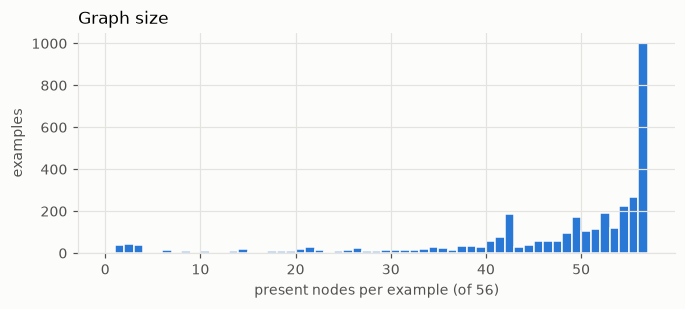

Examples: 3,472 from 42 participants; median 52 of 56 nodes present


In [8]:
fig, ax = plt.subplots(figsize=(7.5, 3.2))
im = ax.imshow(npres.mean(axis=0).T, aspect="auto", cmap="Blues", vmin=0, vmax=1)
ax.set_yticks(range(len(mods)), mods); ax.set_xticks(range(7), [str(d) for d in range(-6, 1)])
ax.set_xlabel("window day (0 = target day)"); ax.set_title("Share of examples in which each node is present"); ax.grid(False)
for i in range(7):
    for j in range(len(mods)):
        ax.text(i, j, f"{npres[:, i, j].mean():.0%}", ha="center", va="center", fontsize=7.5,
                color="white" if npres[:, i, j].mean() > 0.6 else TEXT)
save(fig, "node_presence"); plt.show()
per_example = npres.sum(axis=(1, 2))
fig, ax = plt.subplots(figsize=(7, 2.6))
ax.hist(per_example, bins=range(0, 58), color=BLUE, edgecolor=SURFACE)
ax.set(xlabel="present nodes per example (of 56)", ylabel="examples", title="Graph size")
save(fig, "nodes_per_example"); plt.show()
idx = pd.read_csv(OUT / "cs224w_2022_only" / "examples_index.csv")
print(f"Examples: {len(idx):,} from {idx.id.nunique()} participants; median {np.median(per_example):.0f} of 56 nodes present")

## 7. Output

In [9]:
print("graph_inputs.npz")
print(f"  node_features   {nf.shape}: examples x days x modality nodes x features (padded to 13)")
print(f"  feature_present {fp.shape}, node_present {npres.shape}")
print(f"  y               {g['y'].shape}: log(1 + LH), log(1 + E3G) on the target day (NaN if not measured)")
print("examples_index.csv: id, study_interval, day_in_study, split_by_time (leave-one-subject-out uses id)")

graph_inputs.npz
  node_features   (3472, 7, 8, 13): examples x days x modality nodes x features (padded to 13)
  feature_present (3472, 7, 8, 13), node_present (3472, 7, 8)
  y               (3472, 2): log(1 + LH), log(1 + E3G) on the target day (NaN if not measured)
examples_index.csv: id, study_interval, day_in_study, split_by_time (leave-one-subject-out uses id)
